batchnorm toy but using pytorch
- https://arxiv.org/pdf/2105.07576

In [82]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import json

torch.manual_seed(42);

In [2]:
%%capture
! [ -f names.txt ] || wget https://raw.githubusercontent.com/karpathy/makemore/refs/heads/master/names.txt

In [3]:
df = pd.read_csv("names.txt", header=None)
names = df[0].str.lower()

In [4]:
context_size = 3
X, Y = [], []

for name in names:
	context = [0] * context_size
	for c in name:
		idx = ord(c) - ord("a")
		X.append(context)
		Y.append(idx)
		context = context[1:] + [idx]
	X.append(context)
	Y.append(26)

X = torch.tensor(X)
Y = torch.tensor(Y)

N = len(names)
Ntrain = N * 8 // 10

Xtrain, Ytrain = X[:Ntrain], Y[:Ntrain]
Xval, Yval = X[Ntrain:], Y[Ntrain:]

# expanded similar to pytorch

In [110]:
class Linear:
	def __init__(self, fan_in, fan_out, bias=True):
		self.W = torch.randn((fan_in, fan_out)) / fan_in**0.5
		self.b = torch.zeros((fan_out)) if bias else None
	def __call__(self, x):
		if self.b == None:
			return x @ self.W
		return x @ self.W + self.b
	def parameters(self):
		return [self.W] + ([] if self.b == None else [self.b])

class BatchNorm1d:
	def __init__(self, dim, eps=1e-5, momentum=0.1):
		self.eps = eps
		self.momentum = momentum
		self.training = True # turn off later

		self.gamma = torch.ones(dim)
		self.beta = torch.zeros(dim)

		self.running_mean = torch.zeros(dim)
		self.running_var = torch.ones(dim)

	def __call__(self, x):
		if self.training:
			xmean = x.mean(0, keepdim=True)
			xvar = x.var(0, keepdim=True)
		else:
			xmean = self.running_mean
			xvar = self.running_var
		
		xhat = (x - xmean) / (xvar**0.5 + self.eps)
		self.out = self.gamma * xhat + self.beta

		if self.training:
			with torch.no_grad():
				self.running_mean = (1-self.momentum) * self.running_mean + self.momentum * xmean
				self.running_var = (1-self.momentum) * self.running_var + self.momentum * xvar
		
		return self.out
		
	def parameters(self):
		return [self.beta, self.gamma]

class Tanh:
	def __call__(self, x):
		return torch.tanh(x)
	def parameters(self):
		return []

class Embedding:
	def __init__(self, num_embeddings, embedding_dim):
		self.n = num_embeddings
		self.dim = embedding_dim

		self.embeddings = torch.randn((self.n, self.dim))
	def __call__(self, token_indices):
		return self.embeddings[token_indices]
	def parameters(self):
		return [self.embeddings]

class Flatten:
	def __init__(self, start_dim = 1, end_dim = -1):
		self.start_dim = start_dim
		self.end_dim = end_dim
	def __call__(self, x):
		return torch.flatten(x, self.start_dim, self.end_dim)
	def parameters(self):
		return []

class Sequential:
	def __init__(self, *args):
		self.layers = {}
		for i, arg in enumerate(args):
			self.layers[i] = arg
		self.out = -1
		for p in self.parameters():
			p.requires_grad = True

	def __call__(self, x):
		for i, layer in self.layers.items():
			x = layer(x)
		self.out = x
		return self.out
	def __repr__(self):
		lines = [f"  ({k}): {v}" for k, v in self.layers.items()]
		return "Sequential(\n" + "\n".join(lines) + "\n)"
	def parameters(self):
		return [p for layer in self.layers.values() for p in layer.parameters()]

class CrossEntropyLoss:
	def __call__(self, logits, targets):
		# stability, everything <= 0. keeps exp from exploding
		logits = logits - logits.max(dim=1, keepdim=True).values
		counts = logits.exp()
		probs = counts / counts.sum(dim=1, keepdim=True)

		# probs: (Batch, probs across 27 letters)
		# probs[batch_i, target_letter_i]: (B,)
		return -probs[torch.arange(len(targets)), targets].log().mean()


class AdamOptimizer:
	def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8):
		self.params = list(params)
		self.lr, (self.b1, self.b2), self.eps = lr, betas, eps
		self.m = [torch.zeros_like(p) for p in self.params] # 1st moment
		self.v = [torch.zeros_like(p) for p in self.params] # 2nd moment
		self.t = 0
	
	def zero_grad(self):
		for p in self.params:
			p.grad = None

	@torch.no_grad()
	def step(self):
		self.t += 1

		# loop through all Weights, and respective 1st/2nd moment vals
		for p, m, v in zip(self.params, self.m, self.v):
			g = p.grad

			# weight is fixed/leaf
			if g is None:
				continue

			# m = b1*m + (1-b1)*g
			m = self.b1*m + (1-self.b1)*g
			# v = b2*v + (1-b2)*g²
			v = self.b2*v + (1-self.b2)*g**2

			m_hat = m / (1 - self.b1**self.t) # bias
			v_hat = v / (1 - self.b2**self.t)
			
			p -= self.lr * m_hat / (v_hat.sqrt() + self.eps)

In [113]:
embedding_size = 10
nhidden = 200
nin = embedding_size*context_size


mymodel = Sequential(
	Embedding(27, embedding_size),
	Flatten(),
	Linear(fan_in=nin, fan_out=nhidden),
	BatchNorm1d(nhidden),
	Tanh(),
	Linear(nhidden, 27)
)

criterion = CrossEntropyLoss()
optimizer = AdamOptimizer(mymodel.parameters(), lr=1e-4)

lossi = []

for i in range(10000):
	ixs = torch.randint(0, Xtrain.shape[0], (32,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	logits = mymodel(ctx)

	loss = criterion(logits, target)

	optimizer.zero_grad()
	loss.backward()
	optimizer.step()

	lossi.append(loss.item())

print(loss.item())

2.3025104999542236


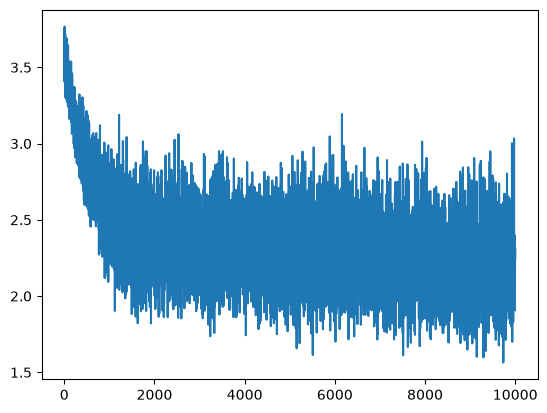

In [114]:
plt.plot(lossi)

# condensed via off-shelf pytorch

In [ ]:
embedding_size = 10
nhidden = 200
nin = embedding_size*context_size


mymodel = nn.Sequential(
	nn.Embedding(27, embedding_size), # token (aka index) to embeddings lookup
	nn.Flatten(), # flatten all embeddings into single vector
	nn.Linear(in_features=nin, out_features=nhidden),
	nn.BatchNorm1d(num_features=nhidden), # match prev out_features, norming across features
	nn.Tanh(),
	nn.Linear(in_features=nhidden, out_features=nhidden),
	nn.BatchNorm1d(num_features=nhidden),
	nn.Tanh(),
	nn.Linear(nhidden, 27)
)


criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(mymodel.parameters(), lr=1e-3)

lossi = []

for i in range(50000):
	ixs = torch.randint(0, Xtrain.shape[0], (32,))
	ctx, target = Xtrain[ixs], Ytrain[ixs]
	logits = mymodel(ctx)

	loss = criterion(logits, target)

	optimizer.zero_grad()
	loss.backward() # calc .grad
	optimizer.step() # move

	lossi.append(loss.item())

print(loss.item())

1.7573490142822266


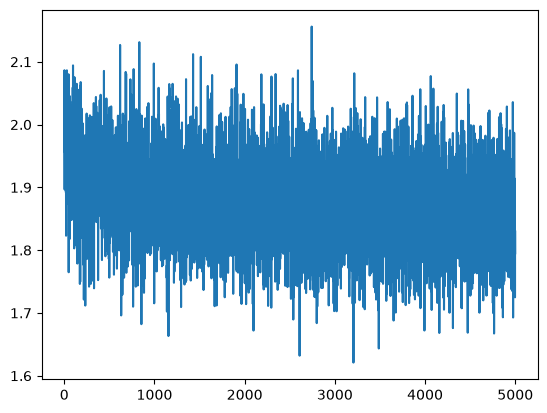

In [74]:
plt.plot(torch.tensor(lossi).view(-1, 5000).mean(0))

In [76]:
alpha = "abcdefghijklmnopqrstuvwxyz."

mymodel.eval() 

for i in range(20):
	ctx = torch.tensor([0] * context_size).unsqueeze(0)
	name = ""

	while len(name) < 20:
		logits = mymodel(ctx)
		probs = torch.softmax(logits, axis=1)
		cidx = torch.multinomial(probs, 1)
		c = alpha[cidx.item()]; name += c
		if c == ".":
			break
		ctx = torch.cat([ctx[:, 1:], cidx], dim=1)
	
	print(name)

jamina.
elina.
ilena.
emmina.
git.
rence.
lee.
chesnee.
jos.
kaleah.
amadejanzeren.
xitlynnjece.
akennah.
kaylyn.
nnalizelynnleett.
valeeharberlena.
toy.
marlinaylin.
ge.
gretzeyne.
